<div style="background: linear-gradient(120deg, #3b1e54 0%, #8a2a6b 62%, #d6336c 100%); color: #ffffff; padding: 30px 34px; border-radius: 14px; margin: 4px 0 10px 0;">
<div style="font-size: 0.8em; letter-spacing: 0.16em; text-transform: uppercase; opacity: 0.85;">Statistical Methods · GSSI · Lecture 3 · 17/11</div>
<div style="font-size: 2.7em; font-weight: 800; line-height: 1.1; margin: 10px 0 8px 0;">Information &amp; Measurement theory</div>
<div style="font-size: 1.15em; opacity: 0.95;">Before computing anything: what do the data contain, and what are you asking them?</div>
</div>

**Reading** · G. Benato, *Statistical Methods for Astroparticle Physics* (GSSI lecture notes), chapters 4-5.

**In this lecture**

1. [Information](#s1)
2. [Measurement theory: which question are you asking?](#s2)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from cycler import cycler
from scipy import stats

# --- house style: one palette for every figure ------------------------------------
PLUM, FUCHSIA, TEAL, AMBER, GREY = "#3b1e54", "#d6336c", "#0b7285", "#e8890c", "#6b7280"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110,
    "axes.prop_cycle": cycler(color=[FUCHSIA, PLUM, TEAL, AMBER]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": "#2a1a3a", "text.color": "#2a1a3a",
    "xtick.color": GREY, "ytick.color": GREY, "lines.linewidth": 2.0,
    "axes.titleweight": "bold", "axes.titlesize": 11, "font.size": 10,
})
rng = np.random.default_rng(2026)   # fixed seed: every run gives the same figures

---
## 1. Information <a id="s1"></a>

When we perform an experiment we collect a huge amount of data that we need to clean and reduce in order to make a statement on the quantity we are interested in. In CUORE we have $\sim 200$ TB of raw data, but our publications just report the half-life of an isotope; CMS and ATLAS have PBs of data, but just measured the Higgs mass and cross section. We need a method to select the **useful information**. But first we need to define the requirements for what we call *information*. It should:

- **increase** with the number of observations,
- be **conditional** on what we want to learn from the experiment: data irrelevant to the hypothesis under test should contain no information,
- be such that the **greater** the information, the **better** the precision of the experiment.

### Likelihood

Take a (real) random variable $\vec{x}$ with PDF $f(\vec{x}\,|\,\vec\theta)$, where $\vec\theta$ is a set of (real) parameters. The set of allowed values of $\vec{x}$ is $\Omega_{\vec\theta}$, which might depend on $\vec\theta$. Suppose we have $n$ measurements $\vec{x}_1, \dots, \vec{x}_n$. The joint PDF on the measured points is

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**◆ Likelihood**

$$P(\vec{x}\,|\,\vec\theta) = \prod_{i=1}^{n} f(\vec{x}_i\,|\,\vec\theta) = \mathcal{L}(\vec{x}\,|\,\vec\theta) = \mathcal{L}(\vec\theta)$$

It is **no longer a PDF**, because the $\vec{x}_i$ are fixed by the measurement: it is a function of $\vec\theta$, not a PDF in $\vec\theta$.

</div>

### Fisher information

Assume that (1) $\Omega_{\vec\theta}$ does not depend on $\vec\theta$, and (2) $\mathcal{L}$ is regular enough so that $\frac{\partial^2}{\partial\theta_i\,\partial\theta_j}$ and $\int d\vec{x}$ commute. Then

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**◆ Fisher information**

$$I_F(\theta) = E\!\left[\left(\frac{\partial \ln\mathcal{L}(\theta)}{\partial\theta}\right)^{2}\right] = \int_\Omega \left(\frac{\partial\ln\mathcal{L}}{\partial\theta}\right)^{2}\mathcal{L}\,d\vec{x} = -E\!\left[\frac{\partial^2}{\partial\theta^2}\ln\mathcal{L}\right]$$

If $\vec\theta$ has dimension $K$, $I_F$ is a $K \times K$ matrix: $\;[I_F(\vec\theta)]_{ij} = \int_\Omega \frac{\partial\ln\mathcal{L}}{\partial\theta_i}\frac{\partial\ln\mathcal{L}}{\partial\theta_j}\,\mathcal{L}\,d\vec{x} = -E\!\left[\frac{\partial^2}{\partial\theta_i\,\partial\theta_j}\ln\mathcal{L}\right]$.

It is **additive**: $I_N(\vec\theta) = N\,I_1(\vec\theta)$.

</div>

### Statistic and sufficiency

A **statistic** is any new random variable $t = t(\vec{x}_1, \dots, \vec{x}_n)$. For example, the average is a statistic. A statistic $t$ is **sufficient** for $\vec\theta$ if the conditional density $f(\vec{x}\,|\,t)$ is independent of $\vec\theta$. Then there is as much information about $\vec\theta$ in $t$ as in the original data $\vec{x}$, and no other function of the data can give any further information about $\vec\theta$. If $t$ is sufficient, any strictly monotonic function of $t$ is sufficient too.

The set $t = \vec{x}$ is sufficient, since it carries all the initial information. But it provides no data reduction, so it is useless. If $t$ is sufficient, the likelihood factorizes:

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**◆ Sufficient statistic**

$$\mathcal{L}(\vec{x}\,|\,\vec\theta) = g(t, \vec\theta)\;h(\vec{x}) \qquad\qquad g(t, \vec\theta) \propto A(t\,|\,\vec\theta)$$

where $h(\vec{x})$ does not depend on $\vec\theta$ and $A(t|\vec\theta)$ is the conditional probability of $t$ given $\vec\theta$. In general, for any statistic, $\;I_t(\vec\theta) \le I_{\vec{x}}(\vec\theta)$, with equality if and only if $t$ is sufficient: the information provided by a sufficient statistic is the same as that of the original sample $\vec{x}$.

</div>

---
## 2. Measurement theory: which question are you asking? <a id="s2"></a>

Suppose we collect data $\vec{x}$ distributed with a PDF $f(\vec{x}\,|\,\vec\theta)$, and we want to make a statement on one parameter $\theta$ (out of the vector $\vec\theta$). There are four different questions we can ask, and each one requires dedicated statistical and computational methods. Understanding the relation between **question** and **method** is fundamental, and will save you a lot of time (trust me!).

So far the language has been vague on purpose. To be specific we have to choose an approach:

- **Frequentist:** the true value of the parameter $\theta$ is fixed but unknown. We cannot associate a PDF to $\theta$, only to the data $\vec{x}$.
- **Bayesian:** probability is a *degree of belief*, so it applies to a wider range of elements: random variables, (true) parameters of a model, and hypotheses.

| | Frequentist | Bayesian | Method |
|:--|:--|:--|:--|
| **Point estimation** | What is our best estimate for the fixed unknown parameter, i.e. the value $\hat\theta$ closest to the true one? | What is the most probable value of $\theta$? | Find the $\hat\theta$ that maximizes $\mathcal{L}$ (or the posterior): a **minimizer** algorithm, e.g. a gradient follower |
| **Interval estimation** | What interval contains the true value with a predefined probability (e.g. 68%)? Repeat the measurement 100 times: you get 100 different intervals, and the true value is inside 68 of them | What interval of the PDF of $\theta$, $f(\theta)$, contains a given amount of probability (e.g. 68%)? | Study the tails of $\mathcal{L}$ or of the posterior $P(\theta\,\vert\,\vec{x})$. F: study all the combinations of $\theta$ giving $\vec{x}$, with **toy Monte Carlo**. B: **map** the posterior with **Markov chain Monte Carlo** |
| **Goodness of fit** | Does my model provide a suitable description of the data, or is there any indication that it should be modified? What is the probability that a random fluctuation gives a worse fit? | *No sense*: we cannot compare one hypothesis with $N$ unknown ones | An analytical method (e.g. $\chi^2$) plus look-up tables, or **toy Monte Carlo** |
| **Hypothesis testing** | Which of two (or more) alternative hypotheses is true? Assuming $H_0$ is true, what is the probability that the data fake $H_1$ (and vice versa)? In practice: compare the signal strength with the probability of a similarly strong background fluctuation | What is the ratio of the probabilities of $H_0$ and $H_1$? | F: **toy Monte Carlo** + a method to compare the validity of the alternative hypotheses. B: a **multi-dimensional integrator** |

Two pictures to remember. A **minimizer** follows the gradient up to the maximum of the likelihood: it answers *where is the best value?* A **mapper** samples the whole distribution: it answers *how far can the parameters wander and still describe the data?*

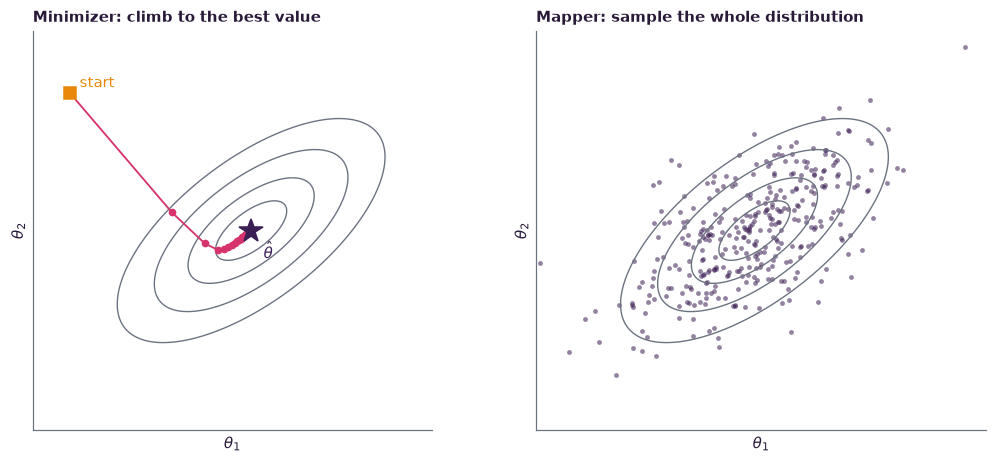

In [2]:
g = np.linspace(-3.2, 3.2, 300)
X, Y = np.meshgrid(g, g)
mu_t = np.array([0.3, 0.0])
C = np.array([[1.0, 0.55], [0.55, 0.7]])
Ci = np.linalg.inv(C)
Z = np.exp(-0.5 * np.einsum("...i,ij,...j", np.dstack([X, Y]) - mu_t, Ci, np.dstack([X, Y]) - mu_t))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.6, 4.1), constrained_layout=True)
for ax in (a1, a2):
    ax.contour(X, Y, Z, levels=[0.1, 0.3, 0.6, 0.85], colors=GREY, linewidths=0.9)
    ax.set(xlabel=r"$\theta_1$", ylabel=r"$\theta_2$", aspect="equal", xticks=[], yticks=[])

# minimizer: gradient ascent on ln L, from a far-away start
p = np.array([-2.6, 2.2])
path = [p]
for _ in range(22):
    p = p - 0.2 * Ci @ (p - mu_t)                  # step along the gradient of ln L
    path.append(p)
path = np.array(path)
a1.plot(*path.T, "-o", color=FUCHSIA, ms=4, lw=1.2)
a1.plot(*path[0], "s", color=AMBER, ms=8)
a1.plot(*mu_t, "*", color=PLUM, ms=16)
a1.text(*(path[0] + [0.15, 0.1]), "start", color=AMBER)
a1.text(mu_t[0] + 0.2, mu_t[1] - 0.45, r"$\hat{\theta}$", color=PLUM, fontweight="bold")
a1.set_title("Minimizer: climb to the best value", loc="left", fontsize=10)

# mapper: sample the whole distribution
pts = rng.multivariate_normal(mu_t, C, 350)
a2.scatter(*pts.T, s=10, color=PLUM, alpha=0.55, lw=0)
a2.set_title("Mapper: sample the whole distribution", loc="left", fontsize=10)
plt.show()

<div style="border-left: 6px solid #d6336c; background: #fdecf3; color: #2a1a3a; padding: 8px 18px; border-radius: 8px; margin: 12px 0;">

**★ What to remember**

- **The likelihood** is a function of the parameters and not a PDF; **Fisher information** measures how much a measurement tells you; a **sufficient statistic** loses nothing.
- **Four questions, four methods:** point estimation, interval estimation, goodness of fit, hypothesis testing.

</div>